DECISON TREE

Accuracy: 1.0

Confusion Matrix:
[[1 0]
 [0 2]]

Prediction: No


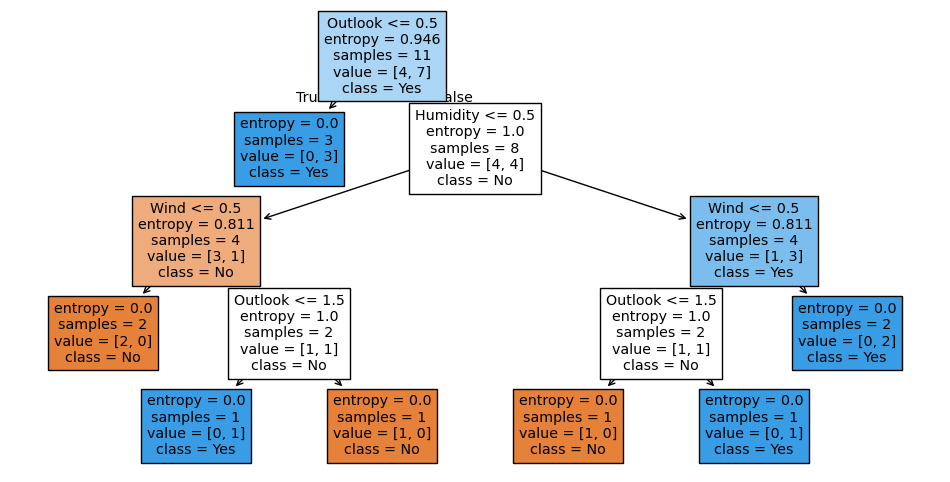

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

# Read data from CSV file
data = pd.read_csv(r"PlayTennis.csv")

# Remove Day column if present
if "Day" in data.columns:
    data = data.drop("Day", axis=1)

# Encode categorical data
encoders = {}

for col in data.columns:
    encoders[col] = LabelEncoder()
    data[col] = encoders[col].fit_transform(data[col])

# Features and target
X = data.drop("Play", axis=1)
y = data["Play"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Decision Tree
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# New sample
new_data = pd.DataFrame({
    "Outlook": ["Sunny"],
    "Temperature": ["Hot"],
    "Humidity": ["High"],
    "Wind": ["Weak"]
})

# Encode new data
for col in new_data.columns:
    new_data[col] = encoders[col].transform(new_data[col])

# Predict
prediction = model.predict(new_data)

print("\nPrediction:",
      encoders["Play"].inverse_transform(prediction)[0])

# Display Decision Tree
plt.figure(figsize=(12, 6))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders["Play"].classes_,
    filled=True
)

plt.show()